# Task 1 model-gap EDA: three untested ideas, each gated by an oracle

รอบสุดท้ายของงาน 1 ลอง 3 ทางที่ยังไม่เคยลอง และแต่ละทางมี oracle (ขอบบน) ก่อน ถ้า oracle บอกว่าไม่มีอะไรให้เก็บก็หยุดตรงนั้น

- **A1 / A2** โมเดล generative ที่จัดการค่าว่างได้ถูกต้อง (naive Bayes ที่ข้ามค่าว่าง และ Gaussian-copula naive Bayes ที่ marginalise ค่าว่างแบบแม่นตรง) ช่วย CatBoost ในแถวที่ว่างหลายช่องไหม
- **A3** ถ้าลบค่าเพิ่ม CatBoost เสียมากกว่าโมเดล copula ไหม
- **A4** มีบริเวณ 2 มิติ (หรือ tail ของอัตราส่วน/ผลคูณ) ที่เป็นคลาสเดียวล้วน ซึ่งกฎช่วงค่า 1 มิติใน `pis/task1_features.py` ยังไม่ครอบคลุมไหม

Metric: F2 ของคลาสคนโกง (`pis.tabular._threshold`) fold: StratifiedKFold 3, seed 342 (fold เดียวกับ pipeline) OOF ของ CatBoost: `outputs/experiments/task1_oof.csv` (`experiments/task1/eda/make_oof.py`, 12 threads) ใช้แค่แถว train ที่มี label ไม่อ่านแถว test

**กฎตัดสิน:** ทางไหนจะคุ้มทำ experiment ต้องได้ **honest** gain ≥ +0.0015 F2 และชนะครบ 3 fold

## Imports

In [1]:
import json, os, sys
from itertools import combinations
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from catboost import CatBoostClassifier
from sklearn.metrics import fbeta_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold

pd.set_option('display.width', 200)  # keep wide tables on one line instead of "..."

## Setup

In [2]:
# Find the repo root (the folder with `run.py`), move there and add it to `sys.path`, so paths like `outputs/...` and `import pis` work wherever the kernel started.
ROOT = Path.cwd().resolve()
while not (ROOT / 'run.py').exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError('run.py not found; open this notebook inside the repo')
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / 'experiments' / 'task1' / 'eda'))

from pis.common import DEFAULT_DATA                                       # ../cpe342-kaggle-main
from pis.tabular import _prepare, _threshold                              # pipeline column prep, cheater-F2 threshold
from pis.task1_features import add_imputed, add_range_rules, fit_imputers
from pis.task2_naive_bayes import SmoothNaiveBayes
from generative import GaussianCopulaNB                                   # experiments/task1/eda/generative.py

BLUE, RED, ORANGE, INK, GRID = '#2a78d6', '#e34948', '#eb6834', '#52514e', '#e5e4df'
MIN_GAIN = 0.0015


def tidy(ax, grid='y'):
    ax.grid(axis=grid, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)


def f2(y, pred):
    return fbeta_score(y, pred, beta=2)


print(f"repo root: {ROOT}")

repo root: C:\Users\acer\Desktop\cpe342\project\player-intelligence-system-cpe342


## Load data & check the OOF

OOF ของ CatBoost ต้องเรียงตรงกับแถว train ที่มี label และ threshold / F2 ต้องตรงกับที่ pipeline รายงานใน `task1_metrics.json` ของ run เดียวกัน fold model 3 ตัวของ run นั้น (`task1_fold{1,2,3}.cbm`) ต้องทายซ้ำได้ OOF เดิมทุกค่า เพราะ A3 ใช้มันทายแถวที่ลบค่าออก

In [3]:
train = pd.read_csv(DEFAULT_DATA / '01_binary_classification' / 'train.csv')
train = train.loc[train['is_cheater'].notna()].reset_index(drop=True)      # labelled rows only, as the pipeline
y = train['is_cheater'].astype(int).to_numpy()
raw, _, _ = _prepare(train, train.drop(columns='is_cheater'), 'is_cheater')  # the 31 raw features, missing kept
feats = list(raw.columns)
oof = pd.read_csv('outputs/experiments/task1_oof.csv')
assert (oof['player_id'].to_numpy() == train['player_id'].to_numpy()).all()
p_cb = oof['probability_1'].to_numpy()
threshold, f2_cb = _threshold(y, p_cb)
reported = json.loads(Path('outputs/experiments/task1_missing_eda_run/task1_metrics.json').read_text())
assert abs(threshold - reported['threshold']) < 1e-12 and abs(f2_cb - reported['oof_score']) < 1e-12

folds = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=342).split(raw, y))   # the pipeline's folds
imputers = fit_imputers(raw, 342)                                          # as pis/task1_features.build (label-free)


def pipeline_features(r):
    return add_range_rules(add_imputed(r, imputers))


x = pipeline_features(raw)
cb_models = [CatBoostClassifier().load_model(f'outputs/experiments/task1_missing_eda_run/task1_fold{k}.cbm') for k in (1, 2, 3)]
check = np.zeros(len(y))
for (a, b), m in zip(folds, cb_models):
    check[b] = m.predict_proba(x.iloc[b])[:, 1]
assert np.abs(check - p_cb).max() < 1e-12, 'fold models do not reproduce the OOF'

n_missing = raw.isna().sum(axis=1).to_numpy()
BUCKETS = ['0-1', '2-3', '4-5', '6-7', '8+']
bucket = np.select([n_missing <= 1, n_missing <= 3, n_missing <= 5, n_missing <= 7], BUCKETS[:4], BUCKETS[4])
print(f"rows {len(y):,} | CatBoost OOF AUC {roc_auc_score(y, p_cb):.4f} | F2 (cheater) {f2_cb:.4f} at threshold {threshold:.4f} | fold models reproduce the OOF")

rows 90,816 | CatBoost OOF AUC 0.8922 | F2 (cheater) 0.8381 at threshold 0.1805 | fold models reproduce the OOF


## A1. Missing-aware generative models

ทั้งสองแบบเทรนบน fold train เท่านั้น ใช้ feature ดิบ 31 ตัว (ค่าว่างยังว่าง)

- **naive Bayes** = `pis.task2_naive_bayes.SmoothNaiveBayes` ตัวเดียวกับงาน 2 (histogram 200 ช่องปรับเรียบ, feature ที่มีค่าไม่เกิน 40 แบบใช้ตารางความถี่) ช่องว่างไม่นับเป็นหลักฐาน ใช้กับ feature ตัวเลขของงาน 1 ได้ตรงๆ
- **Gaussian-copula NB** (`experiments/task1/eda/generative.py`): marginal ต่อคลาสแบบเดียวกับ NB แปลงแต่ละค่าเป็น normal score ด้วย CDF ของคลาสนั้น ประมาณ correlation ของคลาสจากแถวที่มีค่าทั้งคู่ (ทำให้ positive definite) แล้วคิดคะแนนจาก feature ที่มีค่าเท่านั้น (marginal + copula term บน sub-matrix ที่มีค่า) ค่าว่างจึงถูก marginalise แบบแม่นตรง ถ้า R = I จะเท่ากับ NB พอดี (เช็คไว้ข้างล่าง)
- copula แบบ R เต็ม (shrink 1) ทำได้แย่กว่า NB จึงมีอีกแบบที่ดึง R เข้าหา I ครึ่งหนึ่ง (shrink 0.5) ค่านี้เลือกจาก 2 ค่าบน OOF ชุดนี้ จึงเป็นการเลือกบน OOF เล็กน้อย

F2 ในแต่ละกลุ่มใช้ threshold ทั้งชุดของโมเดลนั้น (จูนบน OOF ของมันเอง)

In [4]:
gen = {'naive Bayes': np.zeros(len(y)), 'copula (R full)': np.zeros(len(y)), 'copula (shrink 0.5)': np.zeros(len(y))}
identity_check = np.zeros(len(y))
for a, b in folds:
    gen['naive Bayes'][b] = SmoothNaiveBayes().fit(raw.iloc[a], y[a]).predict_proba(raw.iloc[b])[:, 1]
    identity_check[b] = GaussianCopulaNB(identity=True).fit(raw.values[a], y[a]).predict_proba(raw.values[b])[:, 1]
    gen['copula (R full)'][b] = GaussianCopulaNB().fit(raw.values[a], y[a]).predict_proba(raw.values[b])[:, 1]
    gen['copula (shrink 0.5)'][b] = GaussianCopulaNB(shrink=0.5).fit(raw.values[a], y[a]).predict_proba(raw.values[b])[:, 1]
assert np.abs(identity_check - gen['naive Bayes']).max() < 1e-9, 'copula with R = I should equal naive Bayes'

models = {'CatBoost (current)': p_cb, **gen}
thr = {k: _threshold(y, p)[0] for k, p in models.items()}
overall = pd.DataFrame({k: {'AUC': roc_auc_score(y, p), 'F2 (cheater)': _threshold(y, p)[1], 'threshold': thr[k]} for k, p in models.items()}).T
display(overall.style.format('{:.4f}').set_caption('A1: overall (3-fold OOF, threshold tuned on each model\'s OOF)'))

rows = []
for g in BUCKETS:
    m = bucket == g
    r = {'bucket': g, 'rows': int(m.sum())}
    for k, p in models.items():
        r[(k, 'AUC')] = roc_auc_score(y[m], p[m])
        r[(k, 'F2')] = f2(y[m], p[m] >= thr[k])
    rows.append(r)
by_bucket = pd.DataFrame(rows).set_index('bucket')
by_bucket.columns = pd.MultiIndex.from_tuples([('', 'rows')] + [c for c in by_bucket.columns if c != 'rows'])
by_bucket.style.format('{:.4f}').format('{:,}', subset=[('', 'rows')]).set_caption('A1: AUC and F2 (cheater) per missing-count bucket')

,AUC,F2 (cheater),threshold
CatBoost (current),0.8922,0.8381,0.1805
naive Bayes,0.8408,0.8126,0.1624
copula (R full),0.8205,0.8093,0.1352
copula (shrink 0.5),0.8474,0.8150,0.1876


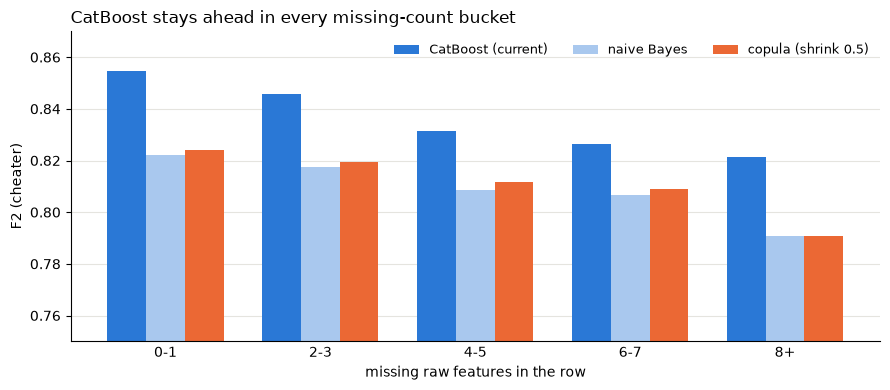

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
xs = np.arange(len(BUCKETS))
for (k, c), off in zip([('CatBoost (current)', BLUE), ('naive Bayes', '#a9c8ee'), ('copula (shrink 0.5)', ORANGE)], (-0.25, 0, 0.25)):
    ax.bar(xs + off, by_bucket[(k, 'F2')], width=0.25, color=c, label=k)
ax.set_xticks(xs, BUCKETS)
ax.set_ylim(0.75, 0.87)
ax.set_xlabel('missing raw features in the row')
ax.set_ylabel('F2 (cheater)')
ax.set_title('CatBoost stays ahead in every missing-count bucket', loc='left')
ax.legend(frameon=False, ncol=3, fontsize=9)
ax.tick_params(axis='x', length=0)
tidy(ax)
plt.tight_layout()
plt.show()

**NOTE:**


CatBoost is best in **every** missing-count bucket, on both AUC and F2, including rows with 8+ missing (F2 0.8215 vs 0.7909 for both generative models). The generative models do fall off a little more slowly: CatBoost's F2 drops 0.033 from 0-1 to 8+ missing, NB's 0.031, the shrunk copula's 0.033. But they start 0.03 lower, so they never catch up.

The Gaussian copula with the full correlation matrix is worse than plain NB (AUC 0.8205 vs 0.8408). The strongest dependence in the data is nonlinear (`level_progression_speed` = level / age × u, see `missing_eda.ipynb` 5b), and a Gaussian copula pushes it too hard. Shrinking the matrix halfway to the identity gives the best generative model (AUC 0.8474, F2 0.8150), still well behind CatBoost (0.8922 / 0.8381). Identity R reproduces `SmoothNaiveBayes` exactly, so the copula code is consistent with the NB the team already uses.

## A2. Oracle, then the honest blend

**Oracle (in-sample, ขอบบน):** แต่ละกลุ่มเลือกโมเดลที่ F2 ดีกว่า (ที่ threshold ของโมเดลนั้น) แล้วคิด F2 ทั้งชุด

**Honest:** ผสม CatBoost กับโมเดล generative (naive Bayes และ copula shrink 0.5) แบบเรขาคณิตหรือเลขคณิต น้ำหนัก CatBoost 0 ถึง 1 ทีละ 0.1
- เลือกน้ำหนักบน 2 fold แล้ววัดบน fold ที่ 3 และจูน threshold ด้วย `_threshold` บน 2 fold นั้นเท่านั้น
- แบบแยกกลุ่ม: เลือกน้ำหนักทีละกลุ่ม (coordinate ascent 2 รอบ เริ่มจาก CatBoost ล้วน) โดยดู F2 ทั้งชุดของ 2 fold ที่ใช้เลือก ซึ่งจูน threshold ใหม่ทุกครั้ง
- แบบน้ำหนักเดียว: น้ำหนักเดียวทุกแถว ใช้วิธีเดียวกัน

ตัวเทียบคือ CatBoost อย่างเดียวที่เลือก threshold แบบเดียวกัน (honest) ข้อจำกัด: OOF ของแถวใน 2 fold ที่ใช้เลือกมาจากโมเดลที่เห็น fold ที่ 3 ตอนเทรน (เป็นแบบเดียวกับ stacking ทั่วไป)

In [6]:
oracle_pred = np.zeros(len(y), int)
pick = {}
for g in BUCKETS:
    m = bucket == g
    pick[g] = max(models, key=lambda k: f2(y[m], models[k][m] >= thr[k]))
    oracle_pred[m] = models[pick[g]][m] >= thr[pick[g]]
print(f"oracle picks: {pick}")
print(f"oracle F2 {f2(y, oracle_pred):.4f} vs CatBoost {f2_cb:.4f} ({f2(y, oracle_pred) - f2_cb:+.4f})")

EPS = 1e-9
WEIGHTS = np.round(np.arange(0, 1.01, 0.1), 1)


def blend(pc, pg, w, kind):
    # w = CatBoost weight. Geometric = weighted log-odds pooling of the two binary distributions.
    if kind == 'arithmetic':
        return w * pc + (1 - w) * pg
    l1 = w * np.log(pc + EPS) + (1 - w) * np.log(pg + EPS)
    l0 = w * np.log(1 - pc + EPS) + (1 - w) * np.log(1 - pg + EPS)
    return 1 / (1 + np.exp(l0 - l1))


def scores_with(w, pg, kind, idx):
    s = np.empty(len(idx))
    for g in BUCKETS:
        m = bucket[idx] == g
        s[m] = blend(p_cb[idx][m], pg[idx][m], w[g], kind)
    return s


def honest(pg, kind, per_bucket):
    pred, per_fold, chosen = np.zeros(len(y), int), [], []
    for a, b in folds:
        if per_bucket:
            w = {g: 1.0 for g in BUCKETS}
            for _ in range(2):
                for g in BUCKETS:
                    w[g] = max(WEIGHTS, key=lambda v: (_threshold(y[a], scores_with({**w, g: v}, pg, kind, a))[1], v))
        else:
            v = max(WEIGHTS, key=lambda v: (_threshold(y[a], blend(p_cb[a], pg[a], v, kind))[1], v))
            w = {g: v for g in BUCKETS}
        t = _threshold(y[a], scores_with(w, pg, kind, a))[0]
        pred[b] = scores_with(w, pg, kind, b) >= t
        per_fold.append(f2(y[b], pred[b]))
        chosen.append(w)
    return f2(y, pred), per_fold, chosen


base_pred, base_fold = np.zeros(len(y), int), []
for a, b in folds:
    base_pred[b] = p_cb[b] >= _threshold(y[a], p_cb[a])[0]
    base_fold.append(f2(y[b], base_pred[b]))
f2_base = f2(y, base_pred)

rows = [{'variant': 'CatBoost alone (honest threshold)', 'F2': f2_base, 'gain': 0.0, 'fold F2': ' / '.join(f'{v:.4f}' for v in base_fold), 'wins': '', 'weights (CatBoost share)': '1.0'}]
for gname in ('naive Bayes', 'copula (shrink 0.5)'):
    for kind in ('geometric', 'arithmetic'):
        for per_bucket in (False, True):
            score, per_fold, chosen = honest(gen[gname], kind, per_bucket)
            ws = ' | '.join('/'.join(f"{w[g]:.1f}" for g in BUCKETS) if per_bucket else f"{w[BUCKETS[0]]:.1f}" for w in chosen)
            rows.append({'variant': f"{gname}, {kind}, {'per bucket' if per_bucket else 'one weight'}", 'F2': score, 'gain': score - f2_base,
                         'fold F2': ' / '.join(f'{v:.4f}' for v in per_fold), 'wins': f"{sum(v > u for v, u in zip(per_fold, base_fold))}/3",
                         'weights (CatBoost share)': ws})
honest_table = pd.DataFrame(rows).set_index('variant')
honest_table.style.format({'F2': '{:.4f}', 'gain': '{:+.4f}'}).set_caption('A2 honest: weights and threshold chosen on 2 folds, scored on the 3rd (weights per fold; per bucket 0-1/2-3/4-5/6-7/8+)')

oracle picks: {'0-1': 'CatBoost (current)', '2-3': 'CatBoost (current)', '4-5': 'CatBoost (current)', '6-7': 'CatBoost (current)', '8+': 'CatBoost (current)'}
oracle F2 0.8381 vs CatBoost 0.8381 (+0.0000)


,F2,gain,fold F2,wins,weights (CatBoost share)
variant,,,,,
CatBoost alone (honest threshold),0.8377,+0.0000,0.8386 / 0.8366 / 0.8380,,1.0
"naive Bayes, geometric, one weight",0.8377,+0.0000,0.8386 / 0.8366 / 0.8380,0/3,1.0 | 1.0 | 1.0
"naive Bayes, geometric, per bucket",0.8379,+0.0002,0.8387 / 0.8364 / 0.8385,2/3,1.0/1.0/1.0/0.8/0.9 | 0.9/1.0/1.0/0.7/0.9 | 0.9/1.0/1.0/0.9/0.9
"naive Bayes, arithmetic, one weight",0.8377,+0.0000,0.8386 / 0.8366 / 0.8380,0/3,1.0 | 1.0 | 1.0
"naive Bayes, arithmetic, per bucket",0.8378,+0.0001,0.8386 / 0.8364 / 0.8384,2/3,1.0/1.0/1.0/0.8/0.8 | 1.0/1.0/1.0/0.8/0.9 | 1.0/1.0/1.0/0.9/0.9
"copula (shrink 0.5), geometric, one weight",0.8377,+0.0000,0.8386 / 0.8366 / 0.8380,0/3,1.0 | 1.0 | 1.0
"copula (shrink 0.5), geometric, per bucket",0.8377,-0.0000,0.8386 / 0.8364 / 0.8380,2/3,1.0/1.0/1.0/0.7/1.0 | 0.9/1.0/1.0/0.6/0.9 | 1.0/1.0/0.9/1.0/1.0
"copula (shrink 0.5), arithmetic, one weight",0.8377,+0.0000,0.8386 / 0.8366 / 0.8380,0/3,1.0 | 1.0 | 1.0
"copula (shrink 0.5), arithmetic, per bucket",0.8375,-0.0002,0.8383 / 0.8362 / 0.8380,0/3,1.0/1.0/1.0/0.8/1.0 | 1.0/1.0/1.0/0.9/1.0 | 1.0/1.0/1.0/1.0/0.9


**NOTE:**


**The oracle is +0.0000.** CatBoost wins every bucket, so picking the better model per bucket picks CatBoost everywhere.

The honest blends confirm it. A single weight always comes out at 1.0 (CatBoost only) on every fold, for both models and both blend types. Per-bucket weights give some weight to the generative model mostly in the 6-7 and 8+ buckets (0.6 to 0.9 CatBoost) and gain at most +0.0002 F2. That happens on 2 of 3 folds, with fold 2 slightly worse. Far below the +0.0015 bar.

## A3. Masking check

เหมือนส่วน 5 ของ `experiments/task2/eda/missing_eda.ipynb`: ลบค่าที่มีอยู่เพิ่ม 3 ช่องในทุกแถว สุ่มเลือก feature ตามสัดส่วนค่าว่างจริงของแต่ละ feature แล้วให้โมเดลของแต่ละ fold ทายแถวใน validation fold ของมันใหม่ CatBoost ใช้ fold model เดิม (คำนวณค่าประมาณของค่าว่างและกฎช่วงค่าใหม่จากค่าที่ลบแล้ว แบบเดียวกับ pipeline) ส่วน NB กับ copula เทรนบน fold train เดิม F2 ใช้ threshold เดิมของแต่ละโมเดล และแบบจูนใหม่

In [7]:
K = 3
rng = np.random.default_rng(342)
known = raw.notna().to_numpy()
weight = 1 - known.mean(axis=0)                                       # real missing share per feature
keys = np.where(known, rng.exponential(size=known.shape) / weight, np.inf)
drop = np.zeros_like(known)
drop[np.arange(len(y))[:, None], np.argsort(keys, axis=1)[:, :K]] = True
raw_m = raw.mask(drop)
x_m = pipeline_features(raw_m)

masked = {k: np.zeros(len(y)) for k in ('CatBoost (current)', 'naive Bayes', 'copula (shrink 0.5)')}
for (a, b), m in zip(folds, cb_models):
    masked['CatBoost (current)'][b] = m.predict_proba(x_m.iloc[b])[:, 1]
    masked['naive Bayes'][b] = SmoothNaiveBayes().fit(raw.iloc[a], y[a]).predict_proba(raw_m.iloc[b])[:, 1]
    masked['copula (shrink 0.5)'][b] = GaussianCopulaNB(shrink=0.5).fit(raw.values[a], y[a]).predict_proba(raw_m.values[b])[:, 1]

rows = []
for k, pm in masked.items():
    p0 = models[k]
    rows.append({'model': k, 'AUC': roc_auc_score(y, p0), 'AUC masked': roc_auc_score(y, pm),
                 'F2': f2(y, p0 >= thr[k]), 'F2 masked (same threshold)': f2(y, pm >= thr[k]), 'F2 masked (retuned)': _threshold(y, pm)[1]})
mask_table = pd.DataFrame(rows).set_index('model')
mask_table['AUC loss'] = mask_table['AUC masked'] - mask_table['AUC']
mask_table['F2 loss'] = mask_table['F2 masked (same threshold)'] - mask_table['F2']
print(f"mean missing per row: {n_missing.mean():.2f} -> {n_missing.mean() + K:.2f}")
mask_table.style.format('{:.4f}').format('{:+.4f}', subset=['AUC loss', 'F2 loss']).set_caption(f'A3: {K} more values removed per row (weighted by the real missing share)')

mean missing per row: 3.71 -> 6.71


,AUC,AUC masked,F2,F2 masked (same threshold),F2 masked (retuned),AUC loss,F2 loss
model,,,,,,,
CatBoost (current),0.8922,0.8648,0.8381,0.8207,0.8213,-0.0274,-0.0173
naive Bayes,0.8408,0.8194,0.8126,0.8001,0.8009,-0.0213,-0.0125
copula (shrink 0.5),0.8474,0.8249,0.8150,0.8025,0.8027,-0.0225,-0.0125


**NOTE:**


With 3 more values removed per row (3.7 → 6.7 missing on average), CatBoost loses more than the generative models: AUC −0.027 vs −0.021 / −0.023, F2 −0.017 vs −0.0125. It still ends far ahead (F2 0.821 vs 0.800 / 0.803). So the missing-aware models do degrade more gracefully, as in Task 2, but at Task 1's real missing rate that never makes them better. Even at 6.7 missing per row, CatBoost stays ahead.

## A4. 2-D pure regions not settled by the 1-D rules

ใช้เฉพาะแถวที่กฎช่วงค่า 1 มิติใน `pis/task1_features.py` ยังไม่ตัดสิน (`n_sure_legit_rules` และ `n_sure_cheat_rules` = 0)

- **ช่อง 2 มิติ:** feature ดิบทุกคู่ (465 คู่) บนแถวที่มีค่าทั้งคู่ แบ่งเป็น grid 20 × 20 ตาม quantile ช่องที่มี ≥ 30 แถว และเป็นคลาสเดียว ≥ 99.5% นับเป็นช่องบริสุทธิ์
- **tail 1 มิติ:** อัตราส่วน a / b (b > 0) และผลคูณ a × b ของทุกคู่ (930 ตัว) หาปลายด้านต่ำและด้านสูงที่ยาวที่สุด (≥ 30 แถว, ตัดที่ค่าไม่ซ้ำ) ที่ยังเป็นคลาสเดียว ≥ 99.5%
- **ตัวเทียบสำหรับ multiple testing:** สลับ label ของแถวกลุ่มเดียวกัน 20 ครั้ง แล้วนับว่าการสุ่มอย่างเดียวให้ช่อง / tail บริสุทธิ์กี่อัน
- **oracle (in-sample):** บังคับแถวในบริเวณที่เจอให้เป็นคลาสนั้น (แถวที่ถูกบังคับทั้งสองทางไม่นับ) นับแถว แถวที่ OOF ทายผิดที่ threshold ของ pipeline และ F2 ที่เปลี่ยน
- **honest:** หาบริเวณจาก 2 fold (ทั้ง edge ของ quantile และจุดตัดของ tail) แล้วบังคับใน fold ที่ 3 เทียบกับ CatBoost ที่เลือก threshold แบบ honest เหมือน A2

In [8]:
settled = ((add_range_rules(raw)['n_sure_legit_rules'] > 0) | (add_range_rules(raw)['n_sure_cheat_rules'] > 0)).to_numpy()
V = raw.to_numpy(dtype=float)
PAIRS = list(combinations(range(V.shape[1]), 2))
DERIVED = []
with np.errstate(divide='ignore', invalid='ignore'):
    for i, j in PAIRS:
        DERIVED.append((f'{feats[i]} / {feats[j]}', np.where(V[:, j] > 0, V[:, i] / V[:, j], np.nan)))
        DERIVED.append((f'{feats[i]} * {feats[j]}', V[:, i] * V[:, j]))
DERIVED_BY_NAME = dict(DERIVED)
print(f"rows settled by the 1-D rules: {settled.sum():,} | left: {(~settled).sum():,} (cheater share {y[~settled].mean():.1%}) | "
      f"{len(PAIRS)} raw pairs, {len(DERIVED)} ratios / products")


def find_regions(rows, labels):
    # Pure 2-D quantile cells and pure 1-D tails, found on `rows` with `labels`.
    regions = []
    for i, j in PAIRS:
        idx = np.flatnonzero(rows & ~np.isnan(V[:, i]) & ~np.isnan(V[:, j]))
        ei = np.unique(np.quantile(V[idx, i], np.linspace(0, 1, 21)[1:-1]))
        ej = np.unique(np.quantile(V[idx, j], np.linspace(0, 1, 21)[1:-1]))
        cell = np.searchsorted(ei, V[idx, i], side='right') * 21 + np.searchsorted(ej, V[idx, j], side='right')
        n = np.bincount(cell, minlength=441); k = np.bincount(cell, weights=labels[idx], minlength=441)
        for c in np.flatnonzero((n >= 30) & ((k >= 0.995 * n) | (k <= 0.005 * n))):
            regions.append({'kind': 'cell', 'name': f'{feats[i]} x {feats[j]}', 'i': i, 'j': j, 'ei': ei, 'ej': ej, 'cell': c,
                            'cls': int(k[c] >= 0.995 * n[c]), 'n': int(n[c])})
    for name, z in DERIVED:
        idx = np.flatnonzero(rows & ~np.isnan(z))
        order = idx[np.argsort(z[idx], kind='stable')]
        for side in ('low', 'high'):
            zz = z[order] if side == 'low' else z[order][::-1]
            yy = labels[order] if side == 'low' else labels[order][::-1]
            cum, length = np.cumsum(yy), np.arange(1, len(yy) + 1)
            for cls, pure in ((1, cum >= 0.995 * length), (0, cum <= 0.005 * length)):
                ends = np.flatnonzero(pure[29:]) + 29                       # prefixes of >= 30 rows
                ends = ends[(ends + 1 == len(zz)) | (zz[np.minimum(ends + 1, len(zz) - 1)] != zz[ends])]  # cut between distinct values
                if len(ends):
                    e = ends.max()
                    regions.append({'kind': 'tail', 'name': f'{name} ({side})', 'z': name, 'side': side, 'cut': zz[e], 'cls': cls, 'n': int(e + 1)})
    return regions


def apply_regions(regions, rows):
    # -1 = not forced; rows hit by regions of both classes are left alone.
    force, conflict = np.full(len(y), -1), np.zeros(len(y), bool)
    for r in regions:
        hit = np.zeros(len(y), bool)
        if r['kind'] == 'cell':
            idx = np.flatnonzero(rows & ~np.isnan(V[:, r['i']]) & ~np.isnan(V[:, r['j']]))
            hit[idx] = (np.searchsorted(r['ei'], V[idx, r['i']], side='right') * 21 + np.searchsorted(r['ej'], V[idx, r['j']], side='right')) == r['cell']
        else:
            z = DERIVED_BY_NAME[r['z']]
            hit = rows & ~np.isnan(z) & ((z <= r['cut']) if r['side'] == 'low' else (z >= r['cut']))
        conflict |= hit & (force >= 0) & (force != r['cls'])
        force[hit & (force < 0)] = r['cls']
    force[conflict] = -1
    return force


regions = find_regions(~settled, y)
pred_pipe = (p_cb >= threshold).astype(int)
rows = []
for label, subset in (('2-D cells', [r for r in regions if r['kind'] == 'cell']), ('ratio / product tails', [r for r in regions if r['kind'] == 'tail']),
                      ('cells + tails', regions)):
    force = apply_regions(subset, ~settled)
    hit = force >= 0
    forced = pred_pipe.copy(); forced[hit] = force[hit]
    rows.append({'regions': label, 'count': len(subset), 'legit / cheater regions': f"{sum(r['cls'] == 0 for r in subset)} / {sum(r['cls'] == 1 for r in subset)}",
                 'rows forced': int(hit.sum()), 'wrong class among forced rows': int((y[hit] != force[hit]).sum()),
                 'OOF wrong there': int((pred_pipe[hit] != force[hit]).sum()), 'F2 change if forced': f2(y, forced) - f2_cb})
a4 = pd.DataFrame(rows).set_index('regions')
a4.style.format({'rows forced': '{:,}', 'F2 change if forced': '{:+.5f}'}).set_caption(f'A4 oracle (in-sample): regions found on all labelled rows, OOF at threshold {threshold:.4f}')

rows settled by the 1-D rules: 28,727 | left: 62,089 (cheater share 41.1%) | 465 raw pairs, 930 ratios / products


,count,legit / cheater regions,rows forced,wrong class among forced rows,OOF wrong there,F2 change if forced
regions,,,,,,
2-D cells,77,27 / 50,"4,100",0,8,+0.00004
ratio / product tails,119,119 / 0,"1,782",103,207,-0.00155
cells + tails,196,146 / 50,"5,759",56,168,-0.00046


In [9]:
pd.DataFrame([{'region': r['name'], 'class': 'cheater' if r['cls'] else 'legit', 'rows': r['n']} for r in regions]) \
    .groupby(['region', 'class'])['rows'].agg(['count', 'sum']).sort_values('sum', ascending=False).head(12) \
    .rename(columns={'count': 'regions', 'sum': 'rows (with overlap)'})

regions  rows (with overlap)
region                                             class                                
account_age_days x friend_network_size             cheater       17                 1717
                                                   legit         24                 1328
account_age_days x reports_received                cheater       15                 1093
friend_network_size / game_sense_score (low)       legit          1                  875
friend_network_size * crosshair_placement (low)    legit          1                  855
friend_network_size / input_consistency_score (... legit          1                  847
friend_network_size / crosshair_placement (low)    legit          1                  836
friend_network_size * game_sense_score (low)       legit          1                  797
friend_network_size / map_knowledge (low)          legit          1                  778
friend_network_size / spray_control_score (low)    legit          1                  766
friend_network_size * map_knowledge (low)          legit          1                  749
headshot_percentage / friend_network_size (high)   legit          1                  744

In [10]:
SHUFFLES = 20
rng = np.random.default_rng(342)
free = np.flatnonzero(~settled)
shuffle_rows = []
for s in range(SHUFFLES):
    labels = y.copy()
    labels[free] = rng.permutation(y[free])
    found = find_regions(~settled, labels)
    shuffle_rows.append({'cells': sum(r['kind'] == 'cell' for r in found), 'tails': sum(r['kind'] == 'tail' for r in found),
                         'rows in regions': sum(r['n'] for r in found)})
shuffled = pd.DataFrame(shuffle_rows)
real = {'cells': sum(r['kind'] == 'cell' for r in regions), 'tails': sum(r['kind'] == 'tail' for r in regions), 'rows in regions': sum(r['n'] for r in regions)}
pd.DataFrame({'real labels': real, 'shuffled: mean': shuffled.mean(), 'shuffled: max': shuffled.max()}).style.format('{:,.1f}') \
    .set_caption(f'A4 multiple-testing baseline: pure regions with labels shuffled ({SHUFFLES} times, unsettled rows only)')

,real labels,shuffled: mean,shuffled: max
cells,77.0,0.0,0.0
tails,119.0,0.0,0.0
rows in regions,"50,714.0",0.0,0.0


In [11]:
rows = []
for label, kinds in (('2-D cells', ('cell',)), ('ratio / product tails', ('tail',)), ('cells + tails', ('cell', 'tail'))):
    pred, per_fold = np.zeros(len(y), int), []
    for a, b in folds:
        in_a, in_b = np.zeros(len(y), bool), np.zeros(len(y), bool)
        in_a[a] = True; in_b[b] = True
        found = [r for r in find_regions(~settled & in_a, y) if r['kind'] in kinds]
        force = apply_regions(found, ~settled & in_b)
        pred[b] = p_cb[b] >= _threshold(y[a], p_cb[a])[0]
        hit = force >= 0
        pred[hit] = force[hit]
        per_fold.append(f2(y[b], pred[b]))
    rows.append({'regions': label, 'F2': f2(y, pred), 'gain vs honest CatBoost': f2(y, pred) - f2_base,
                 'fold F2': ' / '.join(f'{v:.4f}' for v in per_fold), 'wins': f"{sum(v > u for v, u in zip(per_fold, base_fold))}/3"})
a4_honest = pd.DataFrame(rows).set_index('regions')
print(f"honest CatBoost alone: F2 {f2_base:.4f}, folds {' / '.join(f'{v:.4f}' for v in base_fold)}")
a4_honest.style.format({'F2': '{:.4f}', 'gain vs honest CatBoost': '{:+.5f}'}).set_caption('A4 honest: regions found on 2 folds, forced on the 3rd')

honest CatBoost alone: F2 0.8377, folds 0.8386 / 0.8366 / 0.8380


,F2,gain vs honest CatBoost,fold F2,wins
regions,,,,
2-D cells,0.8377,-0.00001,0.8385 / 0.8367 / 0.8379,1/3
ratio / product tails,0.8347,-0.00301,0.8342 / 0.8342 / 0.8358,0/3
cells + tails,0.8362,-0.00148,0.8361 / 0.8356 / 0.8369,0/3


**NOTE:**


**The regions are real.** Shuffled labels give 0 pure cells and 0 pure tails in all 20 shuffles, against 77 cells and 119 tails with the real labels. Almost all of them sit in the account block:
- age × friends cells, both classes;
- age × reports cells, cheaters;
- low tails of ratios and products with `friend_network_size`. These are mostly the "friends < 10 ⇒ legit" boundary (missing from `pis/task1_features.py`) seen through another feature.

**CatBoost already uses them.** The 4,100 rows in the 2-D cells are 100% their class, and the OOF gets only 8 of them wrong; forcing them gains +0.00004 in-sample and −0.00001 honest.

**The tails are worse than useless.** Each tail is ≥ 99.5% pure on its own, but they overlap on the same legit rows while each lets in different cheaters, so their union is only 94% pure (103 cheaters among 1,782 rows). Forcing them costs −0.0016 in-sample and −0.0030 honest, losing on all 3 folds. The combination costs −0.0015 honest. Nothing here reaches +0.0015.

## Summary

| แนวคิด | oracle (in-sample) | honest | ชนะ fold | ผ่านไหม |
|---|---|---|---|---|
| A1/A2 โมเดล generative ที่จัดการค่าว่างถูกต้อง (NB, copula NB) ผสมกับ CatBoost | **+0.0000** (CatBoost ดีที่สุดทุกกลุ่ม) | สูงสุด +0.0002 (NB, เรขาคณิต, น้ำหนักแยกกลุ่ม) | 2/3 | ไม่ผ่าน |
| A3 ลบค่าเพิ่ม 3 ช่อง | CatBoost เสียมากกว่า (F2 −0.017 กับ −0.0125) แต่ยังนำ 0.02 | – | – | ข้อมูลประกอบ |
| A4 บริเวณบริสุทธิ์ 2 มิติ (ช่อง grid) | +0.00004 (4,100 แถว, ผิด 8) | −0.00001 | 1/3 | ไม่ผ่าน |
| A4 tail ของอัตราส่วน/ผลคูณ | −0.0016 | −0.0030 | 0/3 | ไม่ผ่าน |
| A4 ช่อง + tail | −0.0005 | −0.0015 | 0/3 | ไม่ผ่าน |

- **A1:** โมเดล generative ทั้งหมดแพ้ CatBoost ทุกกลุ่มจำนวนช่องที่ว่าง รวมถึงกลุ่ม 8+ ด้วย copula ที่ใช้ correlation เต็มแย่กว่า NB เพราะความสัมพันธ์ที่แรงที่สุด (level / age) ไม่เป็นเส้นตรง ต้องดึง R เข้าหา I ครึ่งหนึ่งจึงดีกว่า NB เล็กน้อย
- **A3:** โมเดลที่ marginalise ค่าว่างเสียคะแนนช้ากว่าจริง แต่ที่อัตราค่าว่างของงานนี้ข้อได้เปรียบนั้นไม่พอจะแซง
- **A4:** โครงสร้าง 2 มิติมีจริง (สลับ label 20 ครั้งไม่เจอเลย) แต่ CatBoost เรียนไปแล้ว ส่วน tail ที่บริสุทธิ์ทีละตัวกลับรวมกันแล้วไม่บริสุทธิ์

**Decision งาน 1: ไม่มีแนวคิดไหนผ่าน (honest ≥ +0.0015 และชนะครบ 3 fold) ไม่มี experiment** CatBoost บนฟีเจอร์ชุดปัจจุบันเก็บสัญญาณที่ 3 แนวคิดนี้หาเจอไปหมดแล้ว รวมกับรอบ 1 ถึง 4 และ missing EDA งาน 1 จึงไม่เหลือทางที่วัดได้ในข้อมูลชุดนี้